In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import librosa
from IPython.display import Audio

from shapesearch.db import connect, list_tracks
from shapesearch.matching.prep import CurveCache, normalize_feature, normalize_sketch
from shapesearch.matching.query import Query, query_curves
from shapesearch.matching.search import search
from shapesearch.audio import load_audio

ROOT = ".."
con = connect(f"{ROOT}/data/shapes.db")
cache = CurveCache.from_database(con)
tracks = {t["track_id"]: t for t in list_tracks(con)}
print(f"{len(cache)} tracks loaded; features: {cache.feature_names}")

25 tracks loaded; features: ['loudness', 'brightness']


In [2]:
def mmss(seconds):
    m, s = divmod(int(round(seconds)), 60)
    return f"{m}:{s:02d}"


def show(response):
    print(f"{len(response.results)} results in {response.search_time_s:.2f} s | weights: {response.weights}")
    for rank, r in enumerate(response.results, 1):
        title = tracks[r.track_id]["title"][:28]
        scores = "  ".join(f"{f[:5]} {s:3.0f}" for f, s in r.feature_scores.items())
        print(f"{rank:>2}. {title:<28} {mmss(r.start_s)}-{mmss(r.end_s)}  score {r.overall_score:5.1f}   ({scores})")


def listen(result, pad=0):
    """Play a result (mono, 22 kHz, so the notebook file stays small)."""
    t = tracks[result.track_id]
    y, sr = load_audio(f"{ROOT}/{t['file_path']}")
    seg = y[int(max(0, result.start_s - pad) * sr): int((result.end_s + pad) * sr)].mean(axis=1)
    return Audio(librosa.resample(seg, orig_sr=sr, target_sr=22050), rate=22050)


def plot_result(result, query):
    """The sketch (dashed) over the matched stretch of each feature, both normalized."""
    curves = query_curves(query)
    feats = list(curves)
    fig, axes = plt.subplots(1, len(feats), figsize=(5 * len(feats), 3), squeeze=False)
    for ax, f in zip(axes[0], feats):
        window = cache.curve(result.track_id, f)[int(result.start_s * 2): int(result.end_s * 2)]
        ax.plot(np.linspace(0, query.duration_s, len(curves[f])), normalize_sketch(curves[f]), "--", label="sketch")
        ax.plot(np.linspace(0, query.duration_s, len(window)), normalize_feature(window, f), label="match")
        ax.set_title(f"{f}: score {result.feature_scores[f]:.0f}")
        ax.legend()
    plt.tight_layout()
    plt.show()

In [6]:
build_then_peak = Query.from_dict({
    "features": {
        "loudness":   {"points": [[0, 0.1], [20, 0.9], [30, 0.9]]},
        "brightness": {"points": [[0, 0.2], [20, 0.8], [30, 0.8]]},
    },
    "duration_s": 30, "top_k": 5,
})
response = search(cache, build_then_peak)
show(response)

5 results in 0.02 s | weights: {'loudness': 0.5, 'brightness': 0.5}
 1. I Could Use a Boost          1:15-1:39  score  88.3   (loudn  92  brigh  84)
 2. BlackTrendMusic - Synth Pop  0:03-0:27  score  88.0   (loudn  90  brigh  86)
 3. JMHBM - Flashy               0:08-0:46  score  86.4   (loudn  92  brigh  80)
 4. BlackTrendMusic - Synth Pop  2:06-2:30  score  84.1   (loudn  86  brigh  82)
 5. JMHBM - 11 MPH               2:04-2:42  score  80.9   (loudn  91  brigh  71)


In [7]:
listen(response.results[0])

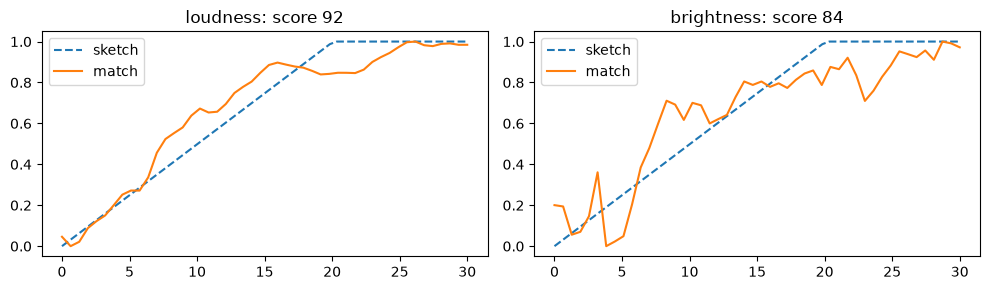

In [8]:
plot_result(response.results[0], build_then_peak)


--- drop (loudness only) ---
5 results in 0.03 s | weights: {'loudness': 1.0}
 1. Vlad Annenkov - Fun Positive 0:02-0:26  score  92.9   (loudn  93)
 2. Vlad Annenkov - Fun Positive 0:46-1:16  score  87.4   (loudn  87)
 3. I Could Use a Boost          0:08-0:32  score  86.8   (loudn  87)
 4. Pacific Rim (feat. Tom Morel 0:16-0:40  score  84.7   (loudn  85)
 5. JMHBM - 11 MPH               2:09-2:39  score  83.6   (loudn  84)


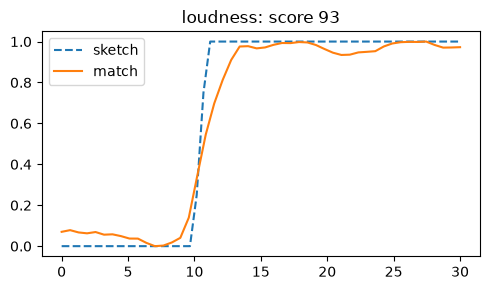


--- fade out (loudness only) ---
5 results in 0.01 s | weights: {'loudness': 1.0}
 1. VADE - Demonic Dong - 9_21_2 1:17-1:54  score  97.9   (loudn  98)
 2. VADE - Demonic Dong - 9_21_2 0:58-1:36  score  96.8   (loudn  97)
 3. human gazpacho - The Undermo 4:15-4:39  score  93.7   (loudn  94)
 4. Vlad Annenkov - Fresh Motiva 1:54-2:18  score  88.2   (loudn  88)
 5. JMHBM - Flashy               1:57-2:21  score  87.4   (loudn  87)


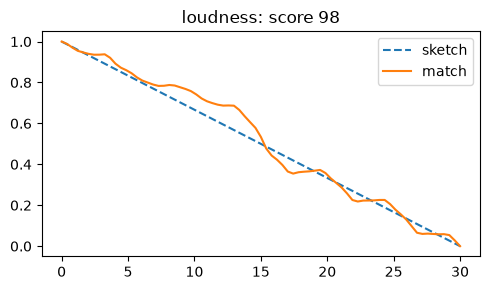


--- flat (loudness only) ---
5 results in 0.01 s | weights: {'loudness': 1.0}
 1. human gazpacho - Memories of 3:02-3:26  score 100.0   (loudn 100)
 2. human gazpacho - Memories of 2:50-3:14  score  99.9   (loudn 100)
 3. Vlad Annenkov - Soft Industr 1:20-1:44  score  97.8   (loudn  98)
 4. Vlad Annenkov - Fresh Motiva 1:05-1:29  score  95.9   (loudn  96)
 5. Adeline Yeo (HP) - Innovativ 1:48-2:12  score  95.0   (loudn  95)


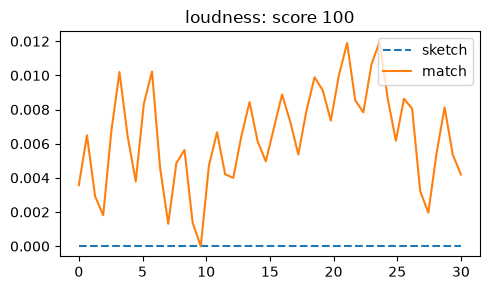

In [11]:
shapes = {
    "drop":     [[0, 0.1], [10, 0.1], [11, 0.9], [30, 0.9]],
    "fade out": [[0, 0.9], [30, 0.1]],
    "flat":     [[0, 0.5], [30, 0.5]],
}
for name, points in shapes.items():
    print(f"\n--- {name} (loudness only) ---")
    q = Query.from_dict({"features": {"loudness": {"points": points}}, "duration_s": 30, "top_k": 5})
    response = search(cache, q)
    show(response)
    plot_result(response.results[0], q)